In [2]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
from cogformer.simulator import ModelFamily
from cogformer.simulator.benchmarks import DDM
from cogformer.simulator.benchmarks.ssms.priors import ddm_priors
from cogformer.simulator.benchmarks.ssms.link_funs import ddm_link_fun

In [6]:
NUM_OBS    = 600
DDM_PARAMS = list(ddm_priors().keys())   # ["v", "a", "z", "tau", "s_v", "s_tau"]

In [7]:
ddm    = DDM()
family = ModelFamily(model=ddm, prior_fun=ddm_priors(), name="DDM")

## 1. Continuous multicollinearity

All regressors are continuous and drawn jointly from
\begin{equation}
X \sim \mathrm{MVN}(0, \Sigma),\quad \Sigma \sim \mathrm{InvWishart}(\nu, I_k).
\end{equation}

* $\nu$: collinearity degree of freedom Low DOF means heavy off-diagonal correlations. High DOF means $\Sigma$ concentrates near I, correlations vanish.

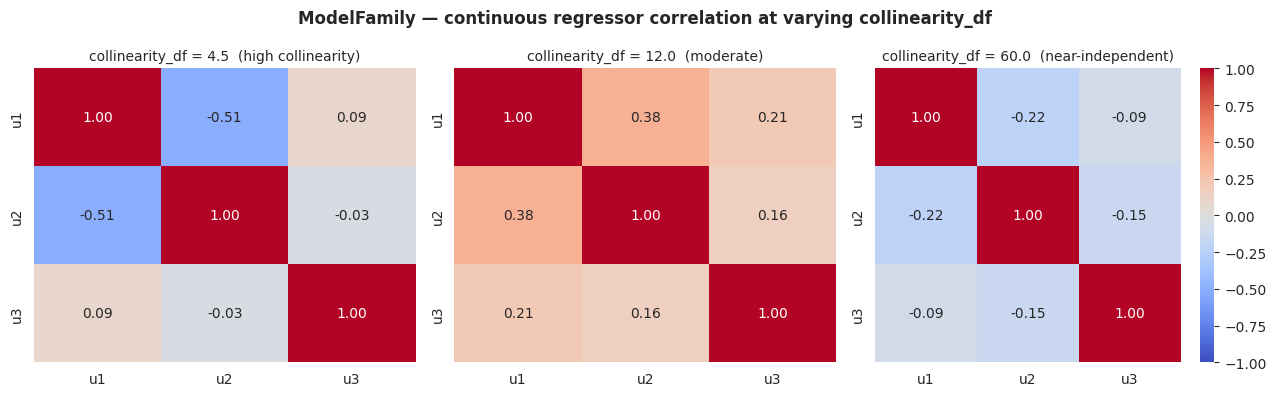

In [8]:
np.random.seed(0)

# Fixed design: 3 continuous regressors, each mapped to all DDM params
design_config_c = {f"u_{i+1}": DDM_PARAMS for i in range(3)}

collinearity_dfs = [4.5, 12.0, 60.0]   # k=3, minimum is k+1=4
df_labels = ["4.5  (high collinearity)", "12.0  (moderate)", "60.0  (near-independent)"]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, df, label in zip(axes, collinearity_dfs, df_labels):
    out = family.sample(
        design_config=design_config_c,
        num_obs=NUM_OBS,
        link_fun=ddm_link_fun(),
        keep_intercept=False,
        discrete_prob=0.0,            # all continuous
        max_num_categories=2,         # block_width=1 → one column per regressor
        collinearity_df=df,
    )
    X    = out["design_matrix"]       # shape (NUM_OBS, 3)
    corr = np.corrcoef(X.T)
    sns.heatmap(corr, ax=ax, vmin=-1, vmax=1, center=0,
                cmap="coolwarm", annot=True, fmt=".2f",
                xticklabels=["u1", "u2", "u3"],
                yticklabels=["u1", "u2", "u3"],
                cbar=(ax is axes[-1]))
    ax.set_title(f"collinearity_df = {label}", fontsize=10)

fig.suptitle("ModelFamily — continuous regressor correlation at varying collinearity_df",
             fontsize=12, fontweight="bold")
plt.tight_layout()

## 2. Discrete category balance

Categories are formed by discretizing a latent MVN column using Dirichlet-sampled quantile cuts.
`category_concentration` controls the Dirichlet concentration: low → one category dominates, high → near-equal bins.

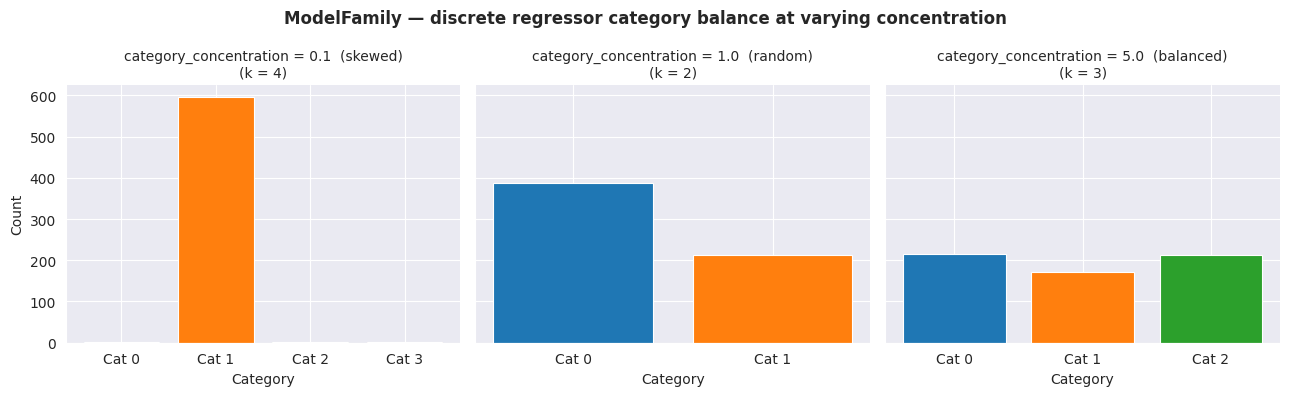

In [9]:
np.random.seed(1)

# Fixed design: 1 discrete regressor
# max_num_categories=4 → k sampled from {2,3,4}, block_width=3 → design matrix (NUM_OBS, 3)
design_config_d = {"u_1": DDM_PARAMS}

concentrations = [0.1, 1.0, 5.0]
conc_labels    = ["0.1  (skewed)", "1.0  (random)", "5.0  (balanced)"]

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)

for ax, conc, clabel in zip(axes, concentrations, conc_labels):
    out     = family.sample(
        design_config=design_config_d,
        num_obs=NUM_OBS,
        link_fun=ddm_link_fun(),
        keep_intercept=False,
        discrete_prob=1.0,            # force discrete
        max_num_categories=4,         # up to 4 categories, block_width=3
        category_concentration=conc,
    )
    X       = out["design_matrix"]    # shape (NUM_OBS, 3) — dummy columns
    # Detect how many categories were actually used
    k       = 1 + int(X.any(axis=0).sum())   # non-zero dummy cols + reference
    dummies = X[:, :k - 1]
    cat_ids = np.where(dummies.any(axis=1), np.argmax(dummies, axis=1) + 1, 0)
    counts  = [(cat_ids == c).sum() for c in range(k)]

    ax.bar([f"Cat {c}" for c in range(k)], counts,
           color=[f"C{c}" for c in range(k)], edgecolor="white", linewidth=0.8)
    ax.set_title(f"category_concentration = {clabel}\n(k = {k})", fontsize=10)
    ax.set_xlabel("Category")
    if ax is axes[0]:
        ax.set_ylabel("Count")
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("ModelFamily — discrete regressor category balance at varying concentration",
             fontsize=12, fontweight="bold")
plt.tight_layout()

## 3. Shared latent structure — continuous + discrete

Both regressors are drawn from the same MVN, so the discrete categories should sit at predictable positions along the continuous axis. Low `collinearity_df` makes this gradient sharp; high `collinearity_df` blurs it toward independence.

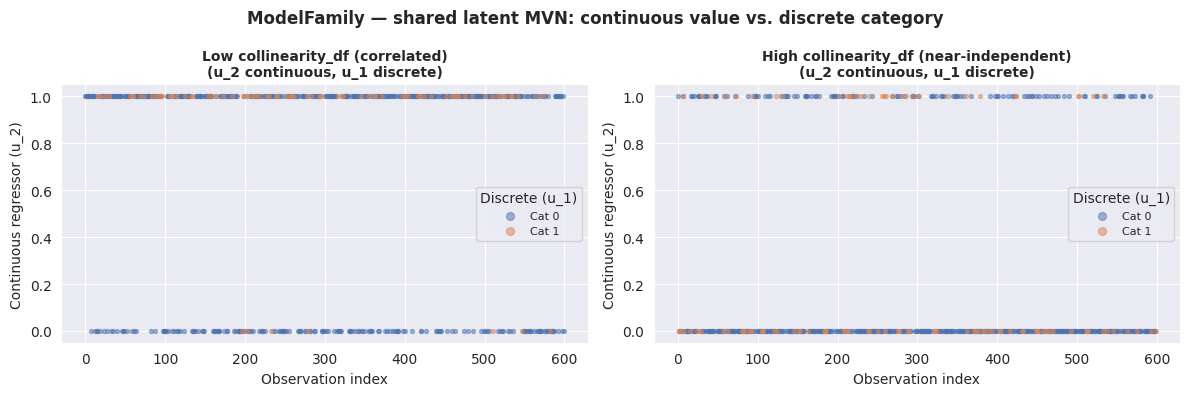

In [10]:
# Fixed design: 2 regressors, discrete_prob=0.5 (each independently 50/50)
# max_num_categories=2 → block_width=1, so design matrix is (NUM_OBS, 2)
# We loop seeds until we get exactly one continuous and one discrete regressor.
design_config_m = {"u_1": DDM_PARAMS, "u_2": DDM_PARAMS}
cat_colors = ["#4C72B0", "#DD8452"]

collinearity_dfs_m = [3.0, 40.0]
titles = ["Low collinearity_df (correlated)", "High collinearity_df (near-independent)"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, df, title in zip(axes, collinearity_dfs_m, titles):
    # Find a seed that gives exactly 1 continuous + 1 discrete
    for seed in range(100):
        np.random.seed(seed)
        out = family.sample(
            design_config=design_config_m,
            num_obs=NUM_OBS,
            link_fun=ddm_link_fun(),
            keep_intercept=False,
            discrete_prob=0.5,
            max_num_categories=2,     # binary discrete, block_width=1
            collinearity_df=df,
            category_concentration=2.0,
        )
        dm = out["discrete_mask"]     # shape (2,): 0=continuous, 1=discrete
        if dm[0] != dm[1]:            # got one of each
            break

    X = out["design_matrix"]          # shape (NUM_OBS, 2)
    cont_idx = int(np.where(dm == 0)[0][0])
    disc_idx = int(np.where(dm == 1)[0][0])

    cont_col = X[:, cont_idx]
    disc_col = X[:, disc_idx].astype(int)   # 0 or 1

    for c, color in enumerate(cat_colors):
        mask = disc_col == c
        ax.scatter(np.where(mask)[0], cont_col[mask],
                   s=8, alpha=0.5, color=color, label=f"Cat {c}")

    ax.set_title(f"{title}\n(u_{cont_idx+1} continuous, u_{disc_idx+1} discrete)",
                 fontsize=10, fontweight="bold")
    ax.set_xlabel("Observation index")
    ax.set_ylabel(f"Continuous regressor (u_{cont_idx+1})")
    ax.legend(title=f"Discrete (u_{disc_idx+1})", markerscale=2, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("ModelFamily — shared latent MVN: continuous value vs. discrete category",
             fontsize=12, fontweight="bold")
plt.tight_layout()